# Task 04: NLP Sentiment Classification on Customer Reviews (TF-IDF)

## Objective
Classify movie reviews as **positive** or **negative**.

**Pipeline:** load reviews → clean text (HTML/punctuation removal, lowercasing, stopword removal, lemmatization) → TF-IDF features (`max_features=5000`) → train **Multinomial Naive Bayes** and **Logistic Regression** → benchmark accuracy → `predict_sentiment()` helper for custom phrases.

**Dataset:** 2,000 labelled movie reviews (1,000 positive, 1,000 negative) from the NLTK `movie_reviews` corpus, saved as `movie_reviews.csv`.

In [1]:
import re, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
for pkg in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)
print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Load the dataset

In [2]:
df = pd.read_csv("movie_reviews.csv")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df["sentiment"].value_counts())
df.head()

Shape: (2000, 2)
Missing values: 0
sentiment
positive    1000
negative    1000
Name: count, dtype: int64


,review,sentiment
0,the verdict : spine-chilling drama from horror...,positive
1,""" the 44 caliber killer has struck again . "" ...",negative
2,in the company of men made a splash at the sun...,positive
3,"in the year 2029 , captain leo davidson ( mark...",negative
4,[note that followups are directed to rec . art...,positive


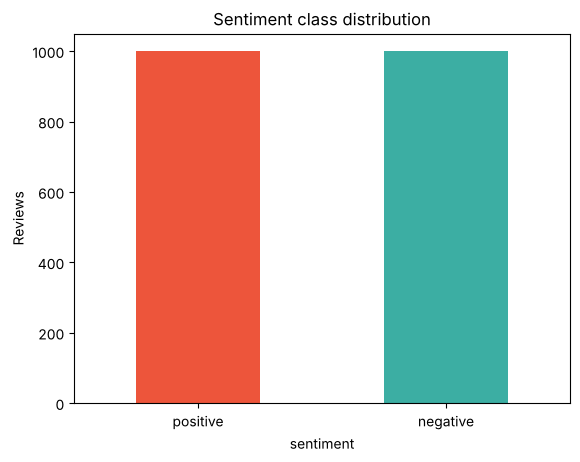

            count   mean    std    min    25%    50%    75%     max
sentiment                                                          
negative   1000.0  705.6  296.7   17.0  510.0  668.5  848.2  2181.0
positive   1000.0  787.1  352.8  130.0  543.5  731.5  957.2  2678.0


In [3]:
df["sentiment"].value_counts().plot(kind="bar", color=["#ED553B", "#3CAEA3"], rot=0)
plt.title("Sentiment class distribution"); plt.ylabel("Reviews"); plt.show()

df["word_count"] = df["review"].str.split().str.len()
print(df.groupby("sentiment")["word_count"].describe().round(1))

## 2. Preprocess the text
Steps: remove HTML tags → lowercase → remove punctuation/numbers → tokenize → remove stopwords → lemmatize.

Negation words (`not`, `no`, `nor`, `never`) are **kept** when removing stopwords, because dropping them would turn "not good" into "good" and flip the meaning.

In [4]:
lemmatizer = WordNetLemmatizer()
NEGATIONS = {"not", "no", "nor", "never"}
stop_words = set(stopwords.words("english")) - NEGATIONS

def clean_text(text):
    text = re.sub(r"<.*?>", " ", text)            # remove HTML tags
    text = text.lower()                           # lowercase
    text = re.sub(r"[^a-z\s]", " ", text)         # remove punctuation, digits
    tokens = text.split()                         # tokenize
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]   # lemmatize
    return " ".join(tokens)

df["clean_review"] = df["review"].apply(clean_text)
print("RAW:    ", df["review"].iloc[0][:200].replace("\n", " "))
print("CLEANED:", df["clean_review"].iloc[0][:200])

RAW:     the verdict : spine-chilling drama from horror maestro stephen king , featuring an outstanding , oscar-winning performance from kathy bates .  geez , french and saunders had a field day when they set 
CLEANED: verdict spine chilling drama horror maestro stephen king featuring outstanding oscar winning performance kathy bates geez french saunders field day set work parodying sorry non british reader may not 


## 3. Train/test split and TF-IDF features

In [5]:
y = (df["sentiment"] == "positive").astype(int)     # 1 = positive, 0 = negative
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["clean_review"], y, test_size=0.2, random_state=42, stratify=y
)

# Fit TF-IDF on training data only (no leakage)
tfidf = TfidfVectorizer(max_features=5000)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)
print("Train matrix:", X_train.shape, "| Test matrix:", X_test.shape)

Train matrix: (1600, 5000) | Test matrix: (400, 5000)


## 4. Train Multinomial Naive Bayes and Logistic Regression

In [6]:
nb_model = MultinomialNB().fit(X_train, y_train)
lr_model = LogisticRegression(max_iter=1000, random_state=42).fit(X_train, y_train)

pred_nb = nb_model.predict(X_test)
pred_lr = lr_model.predict(X_test)
print("Both models trained!")

Both models trained!


## 5. Accuracy benchmarks

In [7]:
acc = {"Multinomial Naive Bayes": accuracy_score(y_test, pred_nb),
       "Logistic Regression": accuracy_score(y_test, pred_lr)}
for n, a in acc.items():
    print(f"{n:25s} accuracy: {a:.4f}")

for name, pred in [("MULTINOMIAL NAIVE BAYES", pred_nb), ("LOGISTIC REGRESSION", pred_lr)]:
    print(f"\n{name}")
    print(classification_report(y_test, pred, target_names=["negative", "positive"]))

Multinomial Naive Bayes   accuracy: 0.8025
Logistic Regression       accuracy: 0.8500

MULTINOMIAL NAIVE BAYES
              precision    recall  f1-score   support

    negative       0.76      0.89      0.82       200
    positive       0.86      0.72      0.78       200

    accuracy                           0.80       400
   macro avg       0.81      0.80      0.80       400
weighted avg       0.81      0.80      0.80       400


LOGISTIC REGRESSION
              precision    recall  f1-score   support

    negative       0.85      0.84      0.85       200
    positive       0.85      0.85      0.85       200

    accuracy                           0.85       400
   macro avg       0.85      0.85      0.85       400
weighted avg       0.85      0.85      0.85       400



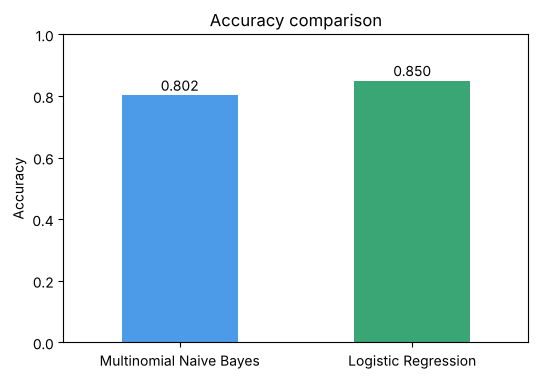

In [8]:
pd.Series(acc).plot(kind="bar", color=["#4c9be8", "#3aa675"], rot=0, ylim=(0, 1), figsize=(6, 4))
plt.title("Accuracy comparison"); plt.ylabel("Accuracy")
for i, v in enumerate(acc.values()): plt.text(i, v + 0.015, f"{v:.3f}", ha="center")
plt.show()

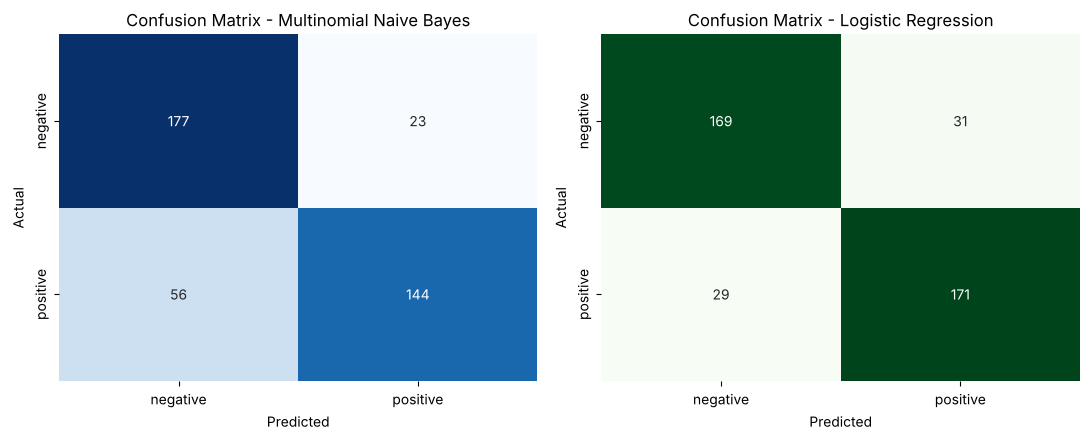

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred, cmap) in zip(axes, [("Multinomial Naive Bayes", pred_nb, "Blues"),
                                         ("Logistic Regression", pred_lr, "Greens")]):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap=cmap, cbar=False,
                xticklabels=["negative", "positive"], yticklabels=["negative", "positive"], ax=ax)
    ax.set_title(f"Confusion Matrix - {name}"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## 6. Most influential words (Logistic Regression)

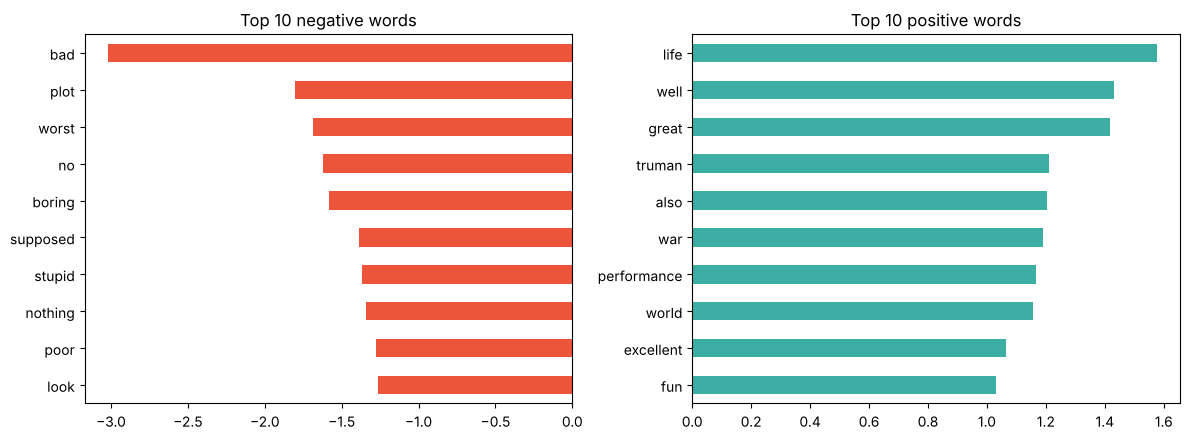

In [10]:
words = np.array(tfidf.get_feature_names_out())
coef = lr_model.coef_[0]
top_pos = pd.Series(coef[np.argsort(coef)[-10:]], index=words[np.argsort(coef)[-10:]])
top_neg = pd.Series(coef[np.argsort(coef)[:10]], index=words[np.argsort(coef)[:10]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
top_neg.sort_values(ascending=False).plot(kind="barh", ax=axes[0], color="#ED553B"); axes[0].set_title("Top 10 negative words")
top_pos.sort_values().plot(kind="barh", ax=axes[1], color="#3CAEA3"); axes[1].set_title("Top 10 positive words")
plt.tight_layout(); plt.show()

## 7. `predict_sentiment()`: test your own phrases
The function applies the **same cleaning and TF-IDF vectorizer** used in training, then returns the label and the model's confidence.

In [11]:
def predict_sentiment(text, model="lr"):
    """Predict sentiment of a custom review. model: 'lr' (Logistic Regression) or 'nb' (Naive Bayes)."""
    clf = lr_model if model == "lr" else nb_model
    vec = tfidf.transform([clean_text(text)])
    proba = clf.predict_proba(vec)[0]
    label = "positive" if proba[1] >= 0.5 else "negative"
    return label, round(float(max(proba)), 3)

samples = [
    "This movie was absolutely fantastic, I loved every minute of it!",
    "Terrible plot, awful acting and a complete waste of time.",
    "A brilliant and moving film with outstanding performances.",
    "The story was boring and I wanted to leave halfway through.",
    "It was not good at all.",
]
for s in samples:
    for m, n in [("lr", "LogReg"), ("nb", "NaiveBayes")]:
        label, conf = predict_sentiment(s, m)
        print(f"[{n:10s}] {label:8s} (conf {conf})  <-  {s}")
    print()

[LogReg    ] positive (conf 0.516)  <-  This movie was absolutely fantastic, I loved every minute of it!
[NaiveBayes] positive (conf 0.579)  <-  This movie was absolutely fantastic, I loved every minute of it!

[LogReg    ] negative (conf 0.882)  <-  Terrible plot, awful acting and a complete waste of time.
[NaiveBayes] negative (conf 0.869)  <-  Terrible plot, awful acting and a complete waste of time.

[LogReg    ] positive (conf 0.814)  <-  A brilliant and moving film with outstanding performances.
[NaiveBayes] positive (conf 0.791)  <-  A brilliant and moving film with outstanding performances.

[LogReg    ] negative (conf 0.634)  <-  The story was boring and I wanted to leave halfway through.
[NaiveBayes] negative (conf 0.679)  <-  The story was boring and I wanted to leave halfway through.

[LogReg    ] positive (conf 0.602)  <-  It was not good at all.
[NaiveBayes] negative (conf 0.51)  <-  It was not good at all.



### Interactive helper
Run the cell below and type your own review. Enter `q` to quit. This works in Jupyter or Colab (it waits for keyboard input).

In [12]:
def interactive_test():
    while True:
        text = input("Enter a review (or 'q' to quit): ")
        if text.strip().lower() == "q":
            break
        label, conf = predict_sentiment(text)
        print(f"  -> {label.upper()} (confidence {conf})\n")

# interactive_test()   # <- remove the leading '#' and run this cell to try your own sentences

## Conclusion

| Model | Test accuracy |
|---|---|
| Multinomial Naive Bayes | 0.8025 |
| Logistic Regression | 0.8500 |

**Key observations**
- Logistic Regression outperformed Naive Bayes by about 5 percentage points. It is also more balanced: Naive Bayes catches most negative reviews (recall 0.89) but misses more positive ones (recall 0.72).
- The most influential words are intuitive (see the bar charts in section 6), which shows the TF-IDF features capture real sentiment signal.
- Limitation: TF-IDF treats text as a bag of words and ignores word order. For example, "It was not good at all." was classified as *positive* by Logistic Regression, because "not" and "good" are scored independently. Using bigrams (`ngram_range=(1, 2)`) or a transformer-based model would handle negation better.
- Results apply to this dataset and this train/test split (`random_state=42`). Movie reviews are long and narrative, so accuracy may differ on short product reviews.